In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
INPUT_DIR = Path("/kaggle/input")

data_dir = None

for path in INPUT_DIR.rglob("raw-img"):
    if path.is_dir():
        data_dir = path
        break

if data_dir is None:
    raise FileNotFoundError(
        "raw-img folder not found. Please add Animals-10 dataset."
    )

print("Dataset Path:", data_dir)

Dataset Path: /kaggle/input/datasets/alessiocorrado99/animals10/raw-img


In [3]:
class_names = sorted([
    folder.name
    for folder in data_dir.iterdir()
    if folder.is_dir()
])

print("Total Animal Classes:", len(class_names))
print("Animal Categories:", class_names)

for animal in class_names:
    folder = data_dir / animal
    images = list(folder.glob("*"))

    print(animal, ":", len(images), "images")

Total Animal Classes: 10
Animal Categories: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
cane : 4863 images
cavallo : 2623 images
elefante : 1446 images
farfalla : 2112 images
gallina : 3098 images
gatto : 1668 images
mucca : 1866 images
pecora : 1820 images
ragno : 4821 images
scoiattolo : 1862 images


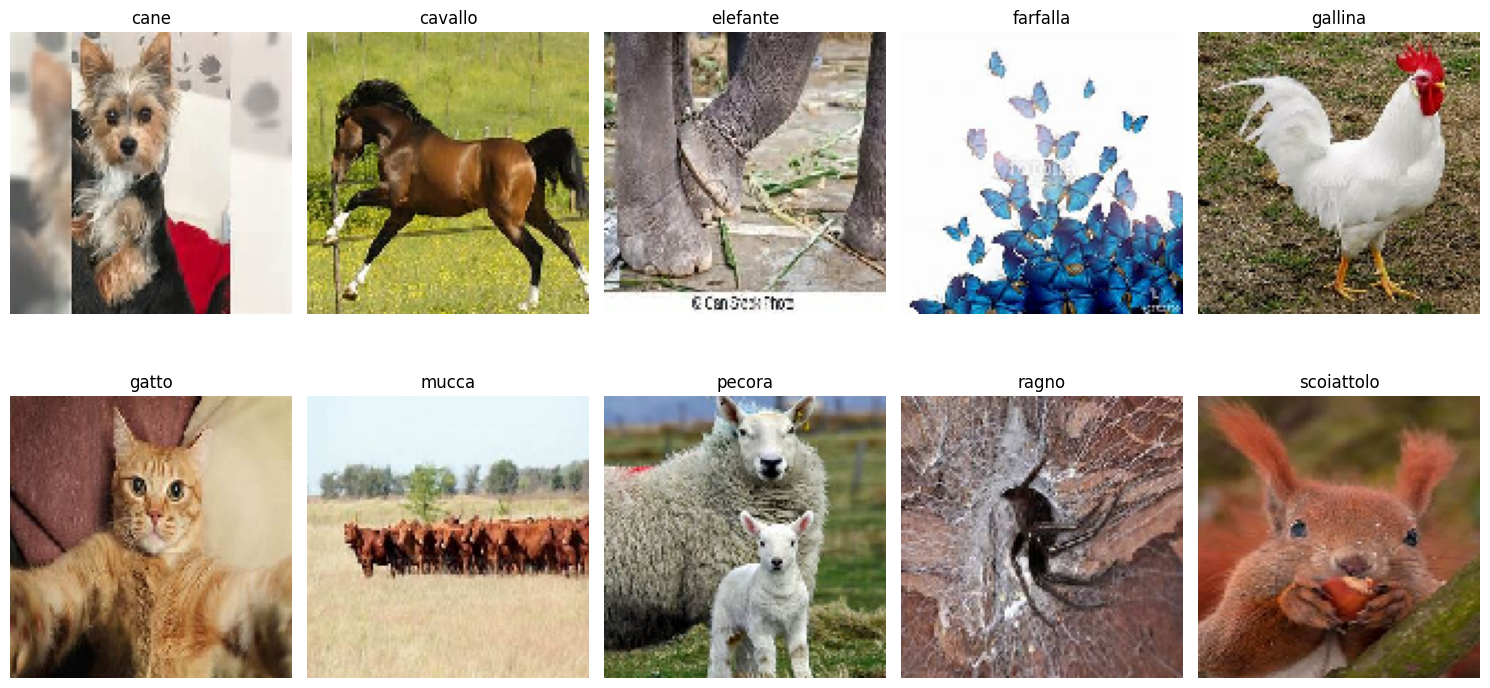

In [4]:
plt.figure(figsize=(15, 8))

for i, animal in enumerate(class_names):
    folder = data_dir / animal

    image_files = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    if not image_files:
        continue

    image = tf.keras.utils.load_img(
        image_files[0],
        target_size=(128, 128)
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(animal)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Number of Classes:", NUM_CLASSES)
print("Classes:", class_names)

Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.
Number of Classes: 10
Classes: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']


In [6]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,750,538 (10.49 MB)

 Trainable params: 2,750,538 (10.49 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_animal_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

EPOCHS = 25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 214s 316ms/step - accuracy: 0.2977 - loss: 1.9798 - val_accuracy: 0.3725 - val_loss: 1.7993
Epoch 2/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.4441 - loss: 1.6130 - val_accuracy: 0.5001 - val_loss: 1.4860
Epoch 3/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.5274 - loss: 1.3904 - val_accuracy: 0.5297 - val_loss: 1.3690
Epoch 4/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.5725 - loss: 1.2703 - val_accuracy: 0.5895 - val_loss: 1.2080
Epoch 5/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.5996 - loss: 1.1791 - val_accuracy: 0.6078 - val_loss: 1.1904
Epoch 6/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6267 - loss: 1.1122 - val_accuracy: 0.6122 - val_loss: 1.1514
Epoch 7/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6426 - loss: 1.0570 - val_accuracy: 0.6401 - val_loss: 1.0656
Epoch 8/25
655/655 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6589 - loss: 1.0034 

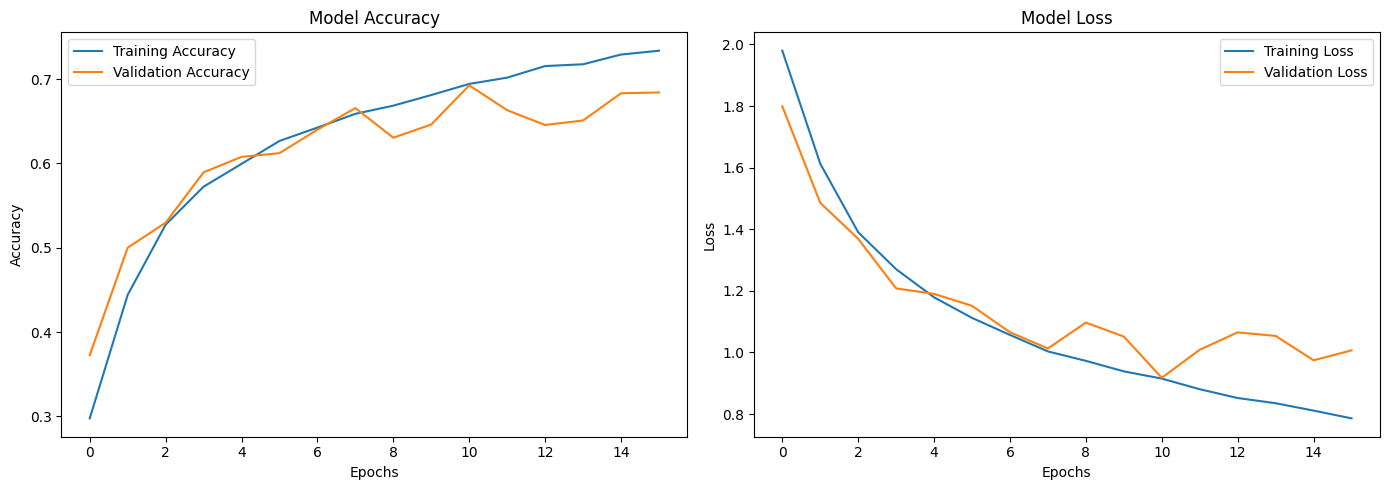

In [14]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
loss, accuracy = model.evaluate(val_ds)

print("Validation Loss:", loss)
print("Validation Accuracy:", round(accuracy * 100, 2), "%")

164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6926 - loss: 0.9179
Validation Loss: 0.9178614020347595
Validation Accuracy: 69.26 %


In [16]:
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

        cane       0.70      0.63      0.66       956
     cavallo       0.63      0.77      0.69       534
    elefante       0.66      0.70      0.68       256
    farfalla       0.67      0.83      0.74       406
     gallina       0.68      0.91      0.78       641
       gatto       0.64      0.30      0.41       303
       mucca       0.55      0.51      0.53       364
      pecora       0.59      0.62      0.60       363
       ragno       0.85      0.82      0.84      1025
  scoiattolo       0.71      0.45      0.55       387

    accuracy                           0.69      5235
   macro avg       0.67      0.65      0.65      5235
weighted avg       0.70      0.69      0.68      5235



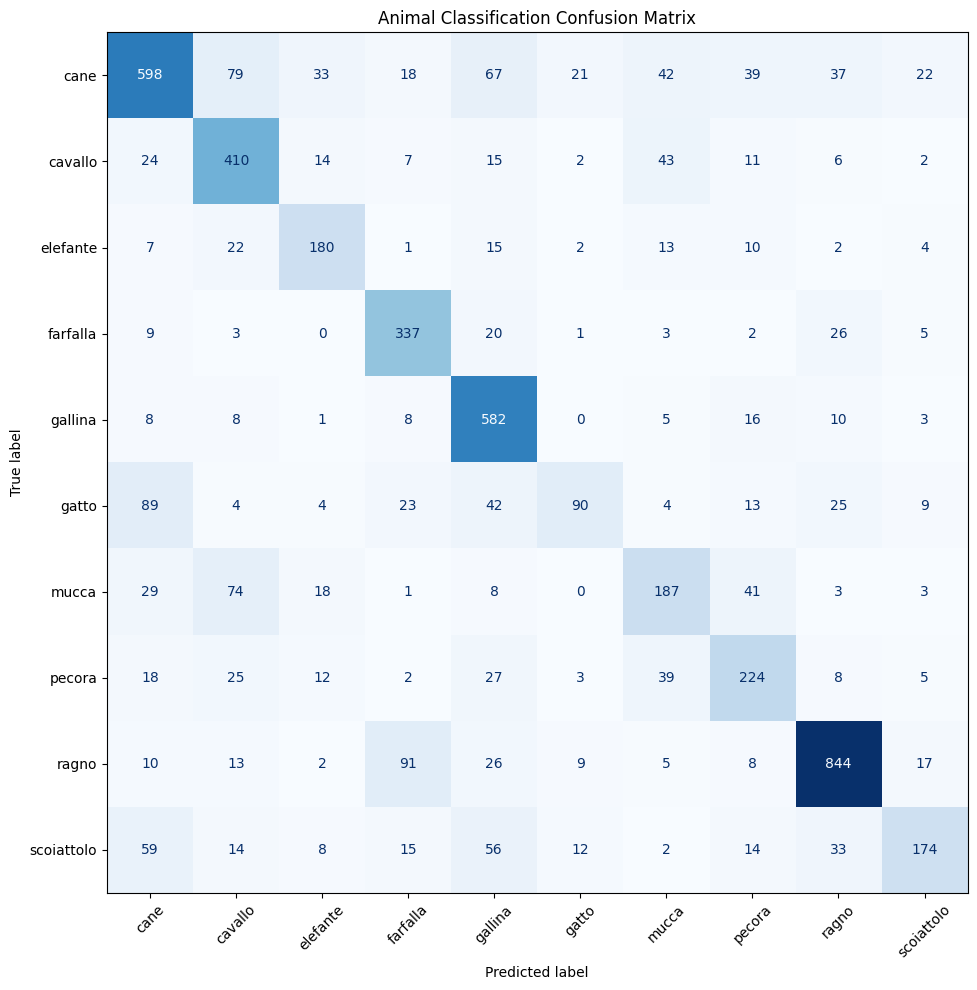

In [17]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Animal Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [24]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMAGE_SIZE = (128, 128)

# These must already exist:
# model
# class_names

In [25]:

def predict_animal(image_path):

    # Check whether image exists
    if not os.path.exists(image_path):
        print("Error: Image file not found:", image_path)
        return None

    # Load image
    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    # Convert image into array
    image_array = tf.keras.utils.img_to_array(image)

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict animal
    predictions = model.predict(image_array, verbose=0)

    # Get predicted class
    predicted_index = np.argmax(predictions[0])

    animal_name = class_names[predicted_index]

    confidence = float(predictions[0][predicted_index] * 100)

    # Display result
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {animal_name}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted Animal:", animal_name)
    print("Confidence:", f"{confidence:.2f}%")

    return animal_name, confidence


In [29]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            print(os.path.join(root, file))

/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIF-e2bexWrojgtQnAPPcUfOWQ.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP---A27bIBcUgX1qkbpZOPswHaFS.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP---ZIdwfUcJeVxnh47zppcQHaFj.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP---ZRsOF7zsMqhW30WeF8-AHaFj.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP---_cJbI6Ei26w5bW1urHewHaCf.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP---cByAiEbIxIAleGo9AqOQAAAA.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP--0C2kq6I68beB3DduLoxMgHaEf.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP--0CZnfLuBERVtzRm2QbB3gHaK4.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP--1QXriWyOTJg-9fEwbznmgHaI4.jpeg
/kaggle/input/datasets/alessiocorrado99/animals10/raw-img/cane/OIP--2uTtzjaszBfEMCROuLN3wHaLH.jpeg
/kaggle/input/

Selected Image: /kaggle/input/datasets/alessiocorrado99/animals10/raw-img/gallina/OIP-SHuw2i1tgctdFKEKodTboAHaFj.jpeg


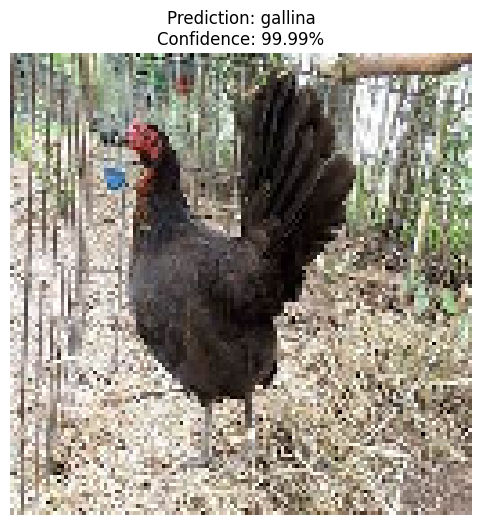

Predicted Animal: gallina
Confidence: 99.99%


In [35]:
import random
from pathlib import Path

data_dir = Path("/kaggle/input")

image_files = list(data_dir.rglob("*.jpg"))
image_files += list(data_dir.rglob("*.jpeg"))
image_files += list(data_dir.rglob("*.png"))

if len(image_files) > 0:

    IMAGE_PATH = str(random.choice(image_files))

    print("Selected Image:", IMAGE_PATH)

    predict_animal(IMAGE_PATH)

else:
    print("No images found in Kaggle input!")